# Round 1

### 2 products:
- Ash Coated Osmium
- Intarian Pepper Root

## Loading Data

In [463]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

price_files = {
  # Day # File
    -2: "data/prices_round_1_day_-2.csv",
    -1: "data/prices_round_1_day_-1.csv",
    0: "data/prices_round_1_day_0.csv"
}

trade_files = {
    -2: "data/trades_round_1_day_-2.csv",
    -1: "data/trades_round_1_day_-1.csv",
    0: "data/trades_round_1_day_0.csv"
}

# Load and offset timestamps by 1M steps
OFFSET = 1_000_000 # each day has 1 million steps
def read_prices(product: str):
        dfs = []
        for i, (day, pf) in enumerate(price_files.items()):
            df = pd.read_csv(pf, sep=';')
            df = df[df['product'] == product].copy()
            df['timestamp'] += i * OFFSET
            df['day'] = day
            df['wall_mid'] = (df[['bid_price_1', 'bid_price_2', 'bid_price_3']].min(axis=1) + df[['ask_price_1', 'ask_price_2', 'ask_price_3']].max(axis=1)) / 2
            df['spread'] = df['ask_price_1'] - df['bid_price_1']
            dfs.append(df)
        return pd.concat(dfs, ignore_index=True).sort_values('timestamp')

def read_trades(symbol: str):
        dfs = []
        for i, (day, pf) in enumerate(trade_files.items()):
            df = pd.read_csv(pf, sep=';')
            df = df[df['symbol'] == symbol].copy()
            df['timestamp'] += i * OFFSET
            df['day'] = day
            
            
            
            
            dfs.append(df)
        return pd.concat(dfs, ignore_index=True).sort_values('timestamp')

# Combine
osmium_prices = read_prices('ASH_COATED_OSMIUM')
osmium_trades = read_trades('ASH_COATED_OSMIUM')
pepper_prices = read_prices('INTARIAN_PEPPER_ROOT')
pepper_trades = read_trades('INTARIAN_PEPPER_ROOT')


osmium_prices['fixed_price'] = 10000



osmium_prices.head(10)
pepper_prices.head(10)
osmium_prices.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   day              30000 non-null  int64  
 1   timestamp        30000 non-null  int64  
 2   product          30000 non-null  object 
 3   bid_price_1      28796 non-null  float64
 4   bid_volume_1     28796 non-null  float64
 5   bid_price_2      19596 non-null  float64
 6   bid_volume_2     19596 non-null  float64
 7   bid_price_3      779 non-null    float64
 8   bid_volume_3     779 non-null    float64
 9   ask_price_1      28799 non-null  float64
 10  ask_volume_1     28799 non-null  float64
 11  ask_price_2      19552 non-null  float64
 12  ask_volume_2     19552 non-null  float64
 13  ask_price_3      747 non-null    float64
 14  ask_volume_3     747 non-null    float64
 15  mid_price        30000 non-null  float64
 16  profit_and_loss  30000 non-null  float64
 17  wall_mid    

In [462]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last"
print(osmium_trades['quantity'].value_counts())
#osmium_prices["wall_mid"].plot()


quantity
6     230
5     224
3     179
4     172
2     160
7      78
9      76
10     75
8      71
Name: count, dtype: int64


/var/folders/n0/zqhkt25d7sv8fn8m4k9ggcc80000gn/T/ipykernel_13033/4029604578.py:12: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



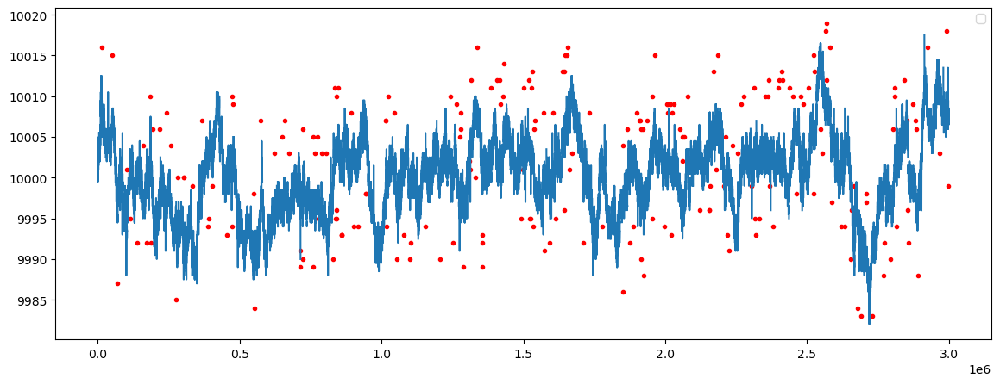

In [454]:
tm = osmium_trades.query("quantity == 5")["timestamp"]
tr = osmium_trades.query("quantity == 5")["price"]
fig, ax = plt.subplots(figsize=(14, 5))
plt.plot(osmium_prices["timestamp"],osmium_prices["wall_mid"])
plt.scatter(tm, tr, marker=".", color="red")


# pepper_prices["spread"] = pepper_prices["ask_price_1"] - pepper_prices["bid_price_1"]
# plt.plot(pepper_prices['timestamp'], pepper_prices["spread"], label="Spread", color='orange')
# plt.plot(pepper_prices['timestamp'], pepper_prices["spread"].rolling(window=10).median(), label="Median Spread", color='cyan')
# plt.plot(pepper_prices['timestamp'], pepper_prices["spread"].rolling(window=20).mean(), label="Average Spread", color='green')
plt.legend()
plt.show()


Confirm data loaded:

In [420]:
osmium_prices.head()
pepper_prices.head()

,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss,wall_mid,spread
0,-2,0,INTARIAN_PEPPER_ROOT,9992.0,17.0,NaN,NaN,NaN,NaN,10005.0,9.0,10008.0,17.0,NaN,NaN,9998.5,0.0,10000.0,13.0
1,-2,100,INTARIAN_PEPPER_ROOT,9995.0,11.0,9992.0,16.0,NaN,NaN,10006.0,11.0,10008.0,16.0,NaN,NaN,10000.5,0.0,10000.0,11.0
2,-2,200,INTARIAN_PEPPER_ROOT,9995.0,12.0,NaN,NaN,NaN,NaN,10008.0,20.0,NaN,NaN,NaN,NaN,10001.5,0.0,10001.5,13.0
3,-2,300,INTARIAN_PEPPER_ROOT,NaN,NaN,NaN,NaN,NaN,NaN,10006.0,10.0,10008.0,21.0,NaN,NaN,10006.0,0.0,NaN,NaN
4,-2,400,INTARIAN_PEPPER_ROOT,9992.0,20.0,NaN,NaN,NaN,NaN,10006.0,12.0,10008.0,20.0,NaN,NaN,9999.0,0.0,10000.0,14.0


## Initial Price Analysis

<Axes: >

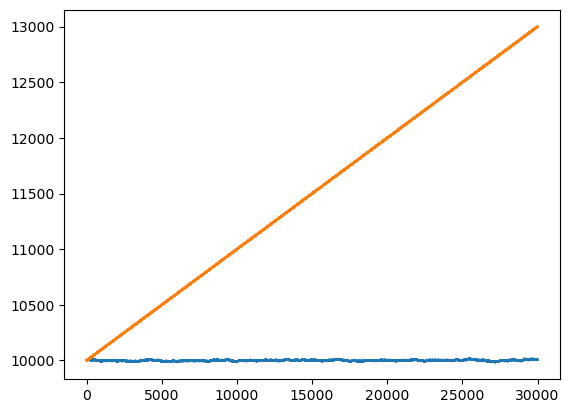

In [255]:
osmium_prices["wall_mid"].plot()
pepper_prices["wall_mid"].plot()

---
# Osmium

In [45]:
osmium_prices[["bid_price_3", "bid_price_2", "bid_price_1", "mid_price", "ask_price_1", "ask_price_2", "ask_price_3"]].describe().round(1)

,bid_price_3,bid_price_2,bid_price_1,mid_price,ask_price_1,ask_price_2,ask_price_3
count,779.0,19596.0,28796.0,30000.0,28799.0,19552.0,747.0
mean,9989.3,9989.8,9992.1,9983.9,10008.3,10010.6,10010.6
std,4.7,4.7,5.0,403.9,5.1,4.7,4.6
min,9976.0,9976.0,9976.0,0.0,9984.0,9992.0,9998.0
25%,9986.0,9987.0,9989.0,9997.0,10005.0,10007.0,10007.0
50%,9990.0,9990.0,9992.0,10000.5,10009.0,10011.0,10011.0
75%,9993.0,9993.0,9995.0,10003.5,10012.0,10014.0,10014.0
max,10004.0,10006.0,10014.0,10023.0,10026.0,10026.0,10025.0


The mid price is very volatile and has a standard deviation of >400! Much higher than the other quotes with a standard deviation of ~5. Additionally, we see that about 3% of the time, there is neither a buy or sell order available.

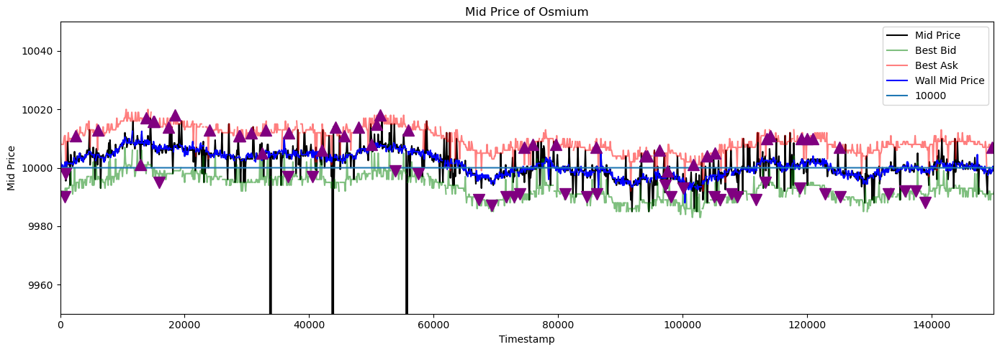

In [260]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Mid Price of Osmium")

plt.plot(osmium_prices['timestamp'], osmium_prices['mid_price'], label="Mid Price", color='black')
plt.plot(osmium_prices['timestamp'],osmium_prices['bid_price_1'], label="Best Bid", color='green', alpha=0.5)
plt.plot(osmium_prices['timestamp'],osmium_prices['ask_price_1'], label="Best Ask", color='red', alpha=0.5)
plt.plot(osmium_prices['timestamp'], osmium_prices['wall_mid'], label="Wall Mid Price", color='blue')
plt.plot(osmium_prices['timestamp'],osmium_prices['fixed_price'],label="10000")


for trade in osmium_trades.itertuples():
    time = trade.timestamp
    price = trade.price
    mark = None
    if trade.price < osmium_prices[['wall_mid']].loc[osmium_prices['timestamp'] == time].values[0]:
        mark = 'v'
    else:
        mark = '^'
    ax.plot(time, price, marker=mark, color='purple', ms=12)

plt.xlabel("Timestamp")
plt.ylabel("Mid Price")
plt.ylim(9950, 10050)

plt.xlim(0,150000)
plt.legend()
plt.tight_layout()

plt.show()

We initially observe that their is not a lot of liquidity in the osmium market. There are multiple periods showing no bid or ask orders in the market, causing the mid price to be extremely volatile. If we want to trade this asset, we need to find a way to not rely on the mid_price from the order book.

## Spread of Osmium

Spread analysis allows us to determine the feasibility of market making strategies that allow us to capture orders by beating the best orders while bidding below and asking above the fair value of the underlying asset. Having a large spread makes and asset a better candidate for this strategy.

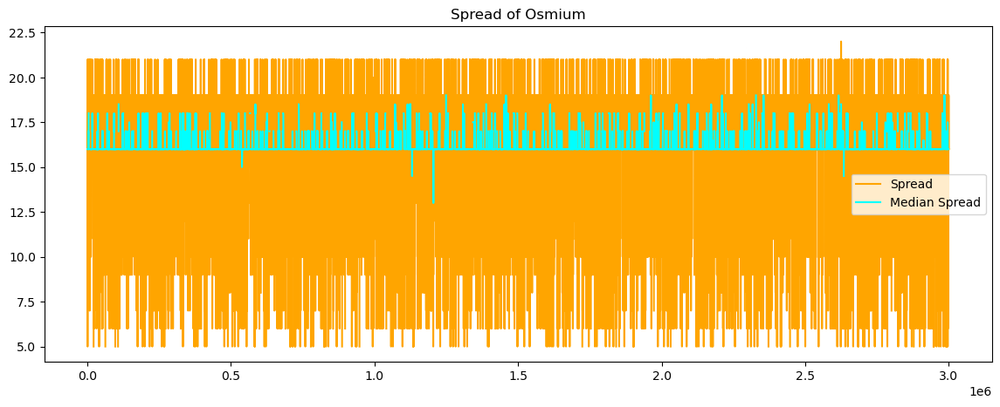

In [48]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Spread of Osmium")

osmium_prices["spread"] = osmium_prices["ask_price_1"] - osmium_prices["bid_price_1"]
plt.plot(osmium_prices['timestamp'], osmium_prices["spread"], label="Spread", color='orange')
plt.plot(osmium_prices['timestamp'], osmium_prices["spread"].rolling(window=10).median(), label="Median Spread", color='cyan')
plt.legend()
plt.show()

In [310]:
from plotly.subplots import make_subplots
import plotly.express as px
import plotly.graph_objects as go



import math
import statistics
def spread_analysis(prices):
    fig = make_subplots(rows=1, cols=3, subplot_titles=("spread", "spread (rolling mean)", "spread (rolling median)"))

    # 2. Create individual Plotly Express figures
    fig1 = px.line(prices, x="timestamp", y="spread", title="spread")
    fig2 = px.line(prices, x="timestamp", y=prices["spread"].rolling(window=10).mean(), title="spread mean")
    fig3 = px.line(prices, x="timestamp", y=prices["spread"].rolling(window=10).median(), title="spread median")

    # 3. Add traces from Express figures to subplots
    for trace in fig1.data:
        fig.add_trace(trace, row=1, col=1)

    for trace in fig2.data:
        fig.add_trace(trace, row=1, col=2)

    for trace in fig3.data:
        fig.add_trace(trace, row=1, col=3)

    fig.update_layout(height=400, width=1000, title_text="Spread Analysis")

    fig.show()

#spread_analysis(osmium_prices)
spread_analysis(pepper_prices)
# fig = px.scatter(pepper_prices, x="wall_mid", y='spread')
# fig.show()
np.polyfit(pepper_prices['timestamp'],pepper_prices['spread'], deg=1)

array([nan, nan])

The spread is around 16 for Osmium.

---
# Pepper

In [320]:
np.polyfit(pepper_prices['timestamp'], pepper_prices['wall_mid'], 1)

array([nan, nan])

In [71]:
pepper_prices[["bid_price_3", "bid_price_2", "bid_price_1", "mid_price", "ask_price_1", "ask_price_2", "ask_price_3"]].describe().round(1)

,bid_price_3,bid_price_2,bid_price_1,mid_price,ask_price_1,ask_price_2,ask_price_3
count,445.0,19413.0,28784.0,30000.0,28850.0,19531.0,467.0
mean,11558.5,11491.9,11494.6,11479.2,11507.5,11508.1,11483.4
std,856.4,865.5,865.6,993.2,866.7,864.9,864.1
min,9996.0,9992.0,9992.0,0.0,10002.0,10008.0,10013.0
25%,10801.0,10740.0,10744.8,10745.5,10756.0,10759.0,10762.5
50%,11615.0,11494.0,11496.0,11497.5,11508.0,11508.0,11431.0
75%,12284.0,12241.0,12244.0,12248.5,12258.8,12256.0,12234.5
max,12979.0,12989.0,12993.0,13007.0,13010.0,13010.0,12995.0


Pepper looks to be even more chaotic. All the prices have a standard deviation of almost 1,000! Let's look at the graph.

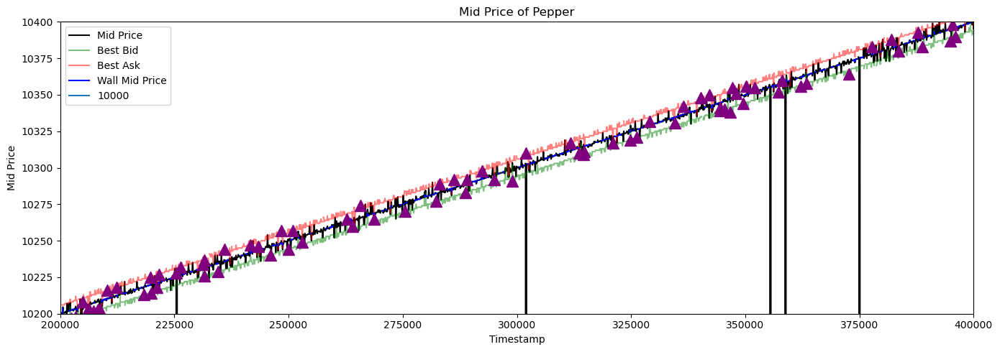

In [72]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Mid Price of Pepper")

plt.plot(pepper_prices['timestamp'], pepper_prices['mid_price'], label="Mid Price", color='black')
plt.plot(pepper_prices['timestamp'],pepper_prices['bid_price_1'], label="Best Bid", color='green', alpha=0.5)
plt.plot(pepper_prices['timestamp'],pepper_prices['ask_price_1'], label="Best Ask", color='red', alpha=0.5)
plt.plot(pepper_prices['timestamp'], (pepper_prices['bid_price_2']+pepper_prices['ask_price_2'])/2, label="Wall Mid Price", color='blue')
plt.axhline(10000,0,label="10000")


for trade in pepper_trades.itertuples():
    time = trade.timestamp
    price = trade.price
    mark = None
    if trade.price < 10000:
        mark = 'v'
    else:
        mark = '^'
    ax.plot(time, price, marker=mark, color='purple', ms=12)

plt.xlabel("Timestamp")
plt.ylabel("Mid Price")
plt.ylim(10200, 10400)

plt.xlim(200000,400000)
plt.legend()
plt.tight_layout()

plt.show()

We actually see with the visual that the price is more stable, following a positive linear relationship. While the initial data description suggested volatility, the visual shows the opposite.

In [96]:
df = pepper_prices
fig = px.line(df, x="timestamp", y=["bid_price_1","bid_price_2","bid_price_3","ask_price_1","ask_price_2","ask_price_3"],
              title="Time Series")
fig.show()

SyntaxError: invalid syntax. Perhaps you forgot a comma? (4236386094.py, line 2)

### Spread Analysis

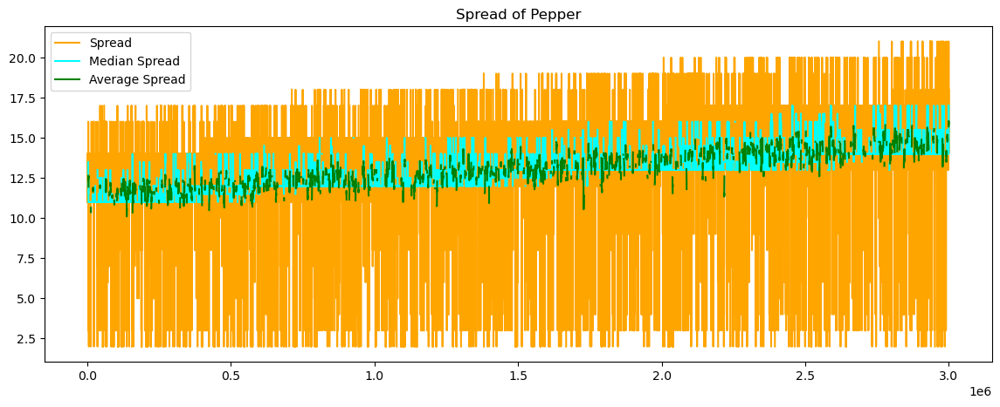

In [343]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Spread of Pepper")

pepper_prices["spread"] = pepper_prices["ask_price_1"] - pepper_prices["bid_price_1"]
plt.plot(pepper_prices['timestamp'], pepper_prices["spread"], label="Spread", color='orange')
plt.plot(pepper_prices['timestamp'], pepper_prices["spread"].rolling(window=10).median(), label="Median Spread", color='cyan')
plt.plot(pepper_prices['timestamp'], pepper_prices["spread"].rolling(window=20).mean(), label="Average Spread", color='green')
plt.legend()
plt.show()

In [93]:
pepper_prices["spread"].describe()

count    27688.000000
mean        13.046699
std          2.627145
min          2.000000
25%         12.000000
50%         13.000000
75%         14.000000
max         21.000000
Name: spread, dtype: float64

We see the spread  of pepper is consistently around 12.5 before later increasing.

In [75]:
pepper_trades["price"].describe()

count     1011.000000
mean     11495.941642
std        879.805548
min       9995.000000
25%      10736.000000
50%      11502.000000
75%      12251.000000
max      13005.000000
Name: price, dtype: float64

## Pepper Strategy

In [339]:
np.polyfit(pepper_prices['spread'].dropna(), pepper_prices["wall_mid"].dropna(),1)

array([  115.06624953, 10001.10333789])

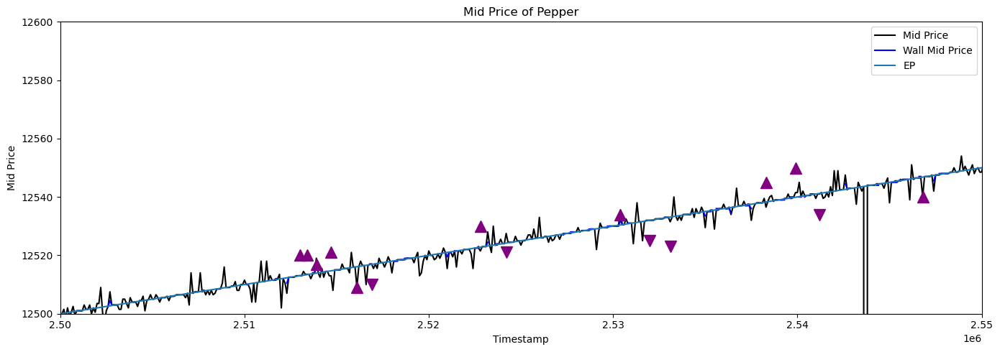

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Mid Price of Pepper")

plt.plot(pepper_prices['timestamp'], pepper_prices['mid_price'], label="Mid Price", color='black')
plt.plot(pepper_prices['timestamp'], (pepper_prices['bid_price_2']+pepper_prices['ask_price_2'])/2, label="Wall Mid Price", color='blue')
#plt.axhline(10000,0,label="10000")
# function EP = 0.00097465198x + 9983.04083
pepper_prices['wall_mid'] = (
    pepper_prices[['bid_price_1', 'bid_price_2', 'bid_price_3']].min(axis=1) + 
    pepper_prices[['ask_price_1', 'ask_price_2', 'ask_price_3']].max(axis=1)
) / 2
ep = 0.001*pepper_prices["timestamp"]+10000
plt.plot(pepper_prices['timestamp'],ep, label="EP")
for trade in pepper_trades.itertuples():
    time = trade.timestamp
    price = trade.price
    mark = None
    if trade.price < pepper_prices['wall_mid'].loc[pepper_prices['timestamp'] == time].values[0]:
        mark = 'v' # a seller selling
    else:
        mark = '^' # a buyer buying
    ax.plot(time, price, marker=mark, color='purple', ms=12)

plt.xlabel("Timestamp")
plt.ylabel("Mid Price")
plt.xlim(2500000,2550000)
plt.ylim(12500,12600)
plt.legend()
plt.tight_layout()

plt.show()

<Axes: >

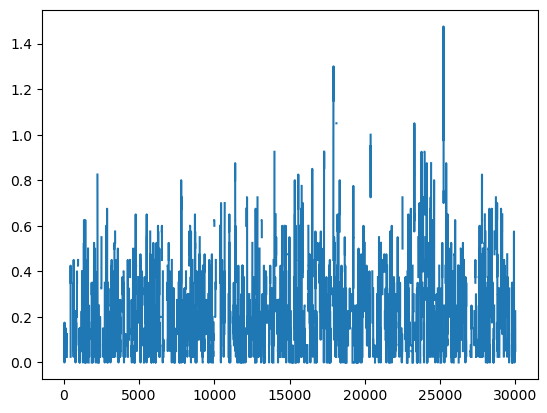

In [145]:
# Minimizing Error

bid_wall = wall_mid = ask_wall = None
pepper_prices['wall_mid'] = (
    pepper_prices[['bid_price_1', 'bid_price_2', 'bid_price_3']].min(axis=1) + 
    pepper_prices[['ask_price_1', 'ask_price_2', 'ask_price_3']].max(axis=1)
) / 2
ep = 0.001*pepper_prices["timestamp"]+10000
error = pepper_prices['wall_mid'] - pepper_prices["mid_price"]
error.rolling(window=20).mean().abs().plot()
#pepper_prices['wall_mid']
#error.plot()

Our strategy here should be to buy our inventory limit of pepper and hold until the end.

But what if we try market taking / making where we have a strong bias against negative inventory? (we should always be close to or at max- only selling if we know we can buy back easily before the mid price exceeds what we sold it for)

In [79]:
pepper_trades["timestamp"].diff().median()

2200.0

There is about 2200 time units between a normal trade, so the price will increase by ~2.2 in this time.

In [345]:
import plotly.graph_objects as go
from imcplots import *
COLORS = {
    "ask_price_3": "#9B0F06",
    "ask_price_2": "#FF5555",
    "ask_price_1": "#FF937E",
    "bid_price_1": "#C1E59F",
    "bid_price_2": "#A3D78A",
    "bid_price_3": "#346739",
    "mid_price": "#0011FF",
    "wall_mid": "#FF00FF"
}
fig = px.line(pepper_prices, x="timestamp", y=[col for col, _ in COLORS.items()]+['mid_price','wall_mid'], color_discrete_map=COLORS,
        line_shape="spline")

fig.show()

In [369]:
fig = px.line(osmium_prices, 'timestamp', 'wall_mid')
fig.show()

In [ ]:
from plotly.subplots import make_subplots
import plotly.express as px
import plotly.graph_objects as go


fig = make_subplots(rows=1, cols=2, subplot_titles=("mid_price", "wall_mid"))

# 2. Create individual Plotly Express figures
fig1 = px.line(osmium_prices, x="timestamp", y="mid_price", title="Mid Price")
fig2 = px.line(osmium_prices, x="timestamp", y="wall_mid", title="Wall Mid Price")

# 3. Add traces from Express figures to subplots
for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)

for trace in fig2.data:
    fig.add_trace(trace, row=1, col=2)

fig.update_layout(height=400, width=800, title_text="Pricing Models: Mid Price vs Wall Mid Price")

fig.show()

count    27644.000000
mean     10000.222761
std          4.753668
min       9982.000000
25%       9997.000000
50%      10000.500000
75%      10003.500000
max      10017.500000
Name: wall_mid, dtype: float64

In [361]:
osmium_prices['mid_price'].describe()

count    30000.000000
mean      9983.870567
std        403.865355
min          0.000000
25%       9997.000000
50%      10000.500000
75%      10003.500000
max      10023.000000
Name: mid_price, dtype: float64

In [351]:
osmium_prices['wall_mid'].describe()

count    27644.000000
mean     10000.222761
std          4.753668
min       9982.000000
25%       9997.000000
50%      10000.500000
75%      10003.500000
max      10017.500000
Name: wall_mid, dtype: float64

In [368]:
import plotly.graph_objects as go
from imcplots import *



fig = go.Figure()
for i in COLORS:
        fig.add_traces(go.Scattergl(
                x=pepper_prices["timestamp"],
                y=pepper_prices[i],
                mode='lines',
                name=i,
                marker=dict(
                        color=COLORS[i],
                        size = 3)
        ))
# fig.add_traces(go.Scatter(
#         x=pepper_prices["timestamp"],
#         y=pepper_prices["bid_price_1"],
#         mode='markers',
#         marker=dict(
#                 color=COLORS['bid_price_1'],
#                 size = 3)
# ))
# fig.add_traces(go.Scatter(
#         x=pepper_prices["timestamp"],
#         y=pepper_prices["bid_price_2"],
#         mode='markers',
#         marker=dict(
#                 color=COLORS['bid_price_2'],
#                 size = 3)
# ))


fig.show()

In [379]:
fig = px.scatter_matrix(osmium_prices, dimensions=["wall_mid",'mid_price',"spread",pepper_prices["spread"],pepper_prices["ask_price_1"]])
fig.show()

#np.polyfit(pepper_prices["spread"].dropna(), osmium_prices["spread"].dropna(),1)

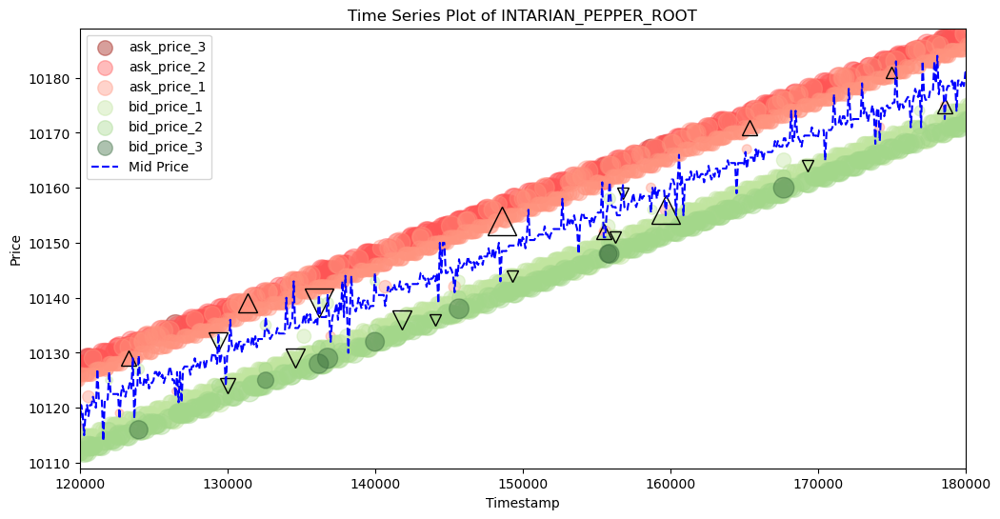

10100


/var/folders/n0/zqhkt25d7sv8fn8m4k9ggcc80000gn/T/ipykernel_13033/4266348107.py:3: FutureWarning:

Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead



In [80]:
from imcplots import *
order_book_plot(pepper_prices, pepper_trades, xmin=120000, xmax=180000)
print(int(pepper_prices[pepper_prices['timestamp']==100000]['mid_price']))

We observe a consistent, positive linear relationship between time and price. We don't see good opportunities to market-make here without hurting our PnL since even if we sell to a really good bid order, we risk losing out on price appreciation before we can recapture our max position again.